In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sqlalchemy import create_engine, text

engine = create_engine(
    "postgresql+psycopg://ektar@localhost:5432/olist_analytics"
)

with engine.connect() as connection:
    database_name = connection.execute(text("SELECT current_database()")).scalar_one()

print(database_name)

olist_analytics


In [3]:
from pathlib import Path

sql_query = Path('../sql/04_cohort_analysis.sql').read_text(encoding="utf-8")

In [4]:
with engine.connect() as conn, conn.begin():
    cohort_activity = pd.read_sql_query(
        sql_query,
        conn
    )

In [5]:
cohort_activity.shape

(278, 5)

In [6]:
cohort_activity.head()

,cohort_month,months_since_first_purchase,active_buyer_count,cohort_size,active_buyer_pct
0,2016-09-01,0,1,1,100.0
1,2016-09-01,1,0,1,0.0
2,2016-09-01,2,0,1,0.0
3,2016-09-01,3,0,1,0.0
4,2016-09-01,4,0,1,0.0


In [7]:
cohort_retention_matrix = cohort_activity.pivot(
    index='cohort_month',
    columns='months_since_first_purchase',
    values='active_buyer_pct'
)

Text(50.833333333333314, 0.5, 'Месяц первой покупки')

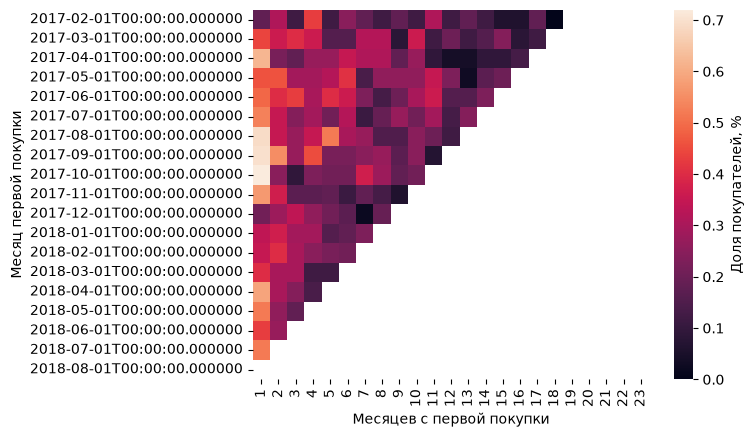

In [8]:
sns.heatmap(
    data=cohort_retention_matrix.loc['2017-02':'2018-08', 1:],
    cbar_kws={'label': 'Доля покупателей, %'}
)

plt.xlabel('Месяцев с первой покупки')
plt.ylabel('Месяц первой покупки')

0% означает месяц без повторных покупок, а пустая клетка - месяц за пределами наблюдений.

In [9]:
month_one_comparison = cohort_activity.query(
    'cohort_month >= "2017-03" and cohort_month <= "2017-04" and months_since_first_purchase == 1'
)

month_one_comparison

,cohort_month,months_since_first_purchase,active_buyer_count,cohort_size,active_buyer_pct
108,2017-03-01,1,11,2503,0.44
126,2017-04-01,1,14,2256,0.62


У апрельской когорты доля активных покупателей 0.62% (14 из 2256) выше мартовской 0.44% (11 из 2503) спустя месяц после первой покупки.